# Qiskit Fall Fest 2026 - Challenge 4: Quantum Correlation Switch
**IBM Quantum - Vishnu Institute of Technology**  
**Name:** Srikar

**Goal:** build two 2-qubit circuits (max 4 gates before measurement, 100 shots each):
- **Part A** - correlated outcomes: mostly `00` and `11`
- **Part B** - opposite outcomes: mostly `01` and `10`
- **Part C** - compare both with histograms and explain the difference

Only workshop gates are used: `H` (Hadamard), `CX` (CNOT) and `X`.

In [1]:
# If Qiskit is not installed (e.g. a fresh Colab runtime), uncomment:
# !pip install qiskit qiskit-aer matplotlib pylatexenc

from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
import matplotlib.pyplot as plt

SHOTS = 100
sim = AerSimulator()

def run(qc, shots=SHOTS, seed=2026):
    """Run a circuit on the Aer simulator and return the counts dictionary."""
    result = sim.run(transpile(qc, sim), shots=shots, seed_simulator=seed).result()
    return result.get_counts()

## Predictions (made before running)

**Part A** (`H` on q0, then `CX` q0 -> q1): the state is the Bell state (|00> + |11>)/sqrt(2). I predict **`00` and `11` dominate**, each close to 50 of 100 shots.

**Part B** (same circuit plus an `X` on q1): the state becomes (|01> + |10>)/sqrt(2). I predict **`01` and `10` dominate**, each close to 50 of 100 shots.

**Will all four outcomes appear?** No. In an ideal, noiseless simulation only two of the four outcomes have non-zero probability in each circuit; the other two should have 0 counts. Within the two allowed outcomes, the split will not be exactly 50/50 because 100 shots is a small sample (statistical fluctuation, roughly +/- 5 counts).

**Why are some outcomes much more frequent than others?** Entanglement ties the two qubits together, so only outcomes consistent with the correlation rule can occur. The impossible ones are not just rare, they have probability zero.

## Part A - Correlated outcomes (`00` and `11`)
Gates: `H(0)`, `CX(0,1)` - 2 gates before measurement.

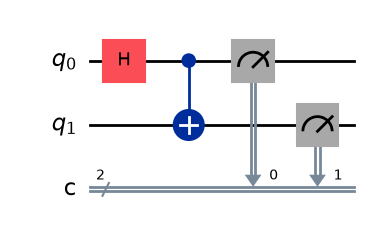

In [2]:
qc_a = QuantumCircuit(2, 2, name="Part A")
qc_a.h(0)            # gate 1: put qubit 0 in superposition
qc_a.cx(0, 1)        # gate 2: entangle qubit 1 with qubit 0 (Bell state)
qc_a.measure([0, 1], [0, 1])

qc_a.draw("mpl")

Part A counts (100 shots): {'00': 55, '11': 45}


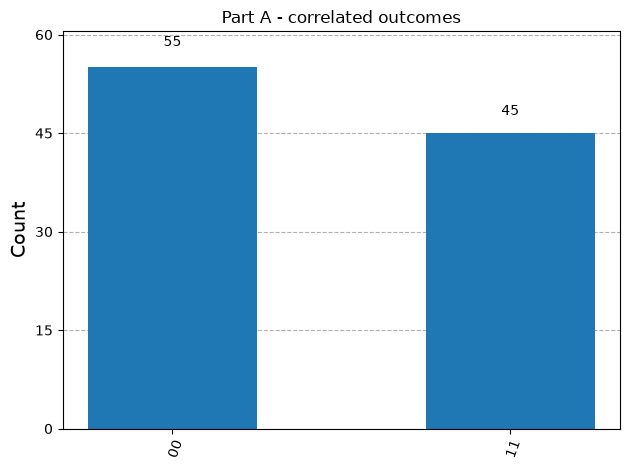

In [3]:
counts_a = run(qc_a)
print("Part A counts (100 shots):", counts_a)
plot_histogram(counts_a, title="Part A - correlated outcomes")

## Part B - Opposite outcomes (`01` and `10`)
Gates: `H(0)`, `CX(0,1)`, `X(1)` - 3 gates before measurement. The only change from Part A is one extra `X` gate on qubit 1.

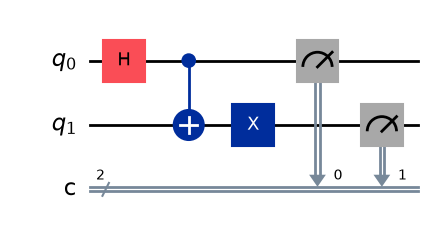

In [4]:
qc_b = QuantumCircuit(2, 2, name="Part B")
qc_b.h(0)            # gate 1: put qubit 0 in superposition
qc_b.cx(0, 1)        # gate 2: entangle (Bell state, same as Part A)
qc_b.x(1)            # gate 3: flip qubit 1 -> correlated becomes opposite
qc_b.measure([0, 1], [0, 1])

qc_b.draw("mpl")

Part B counts (100 shots): {'10': 55, '01': 45}


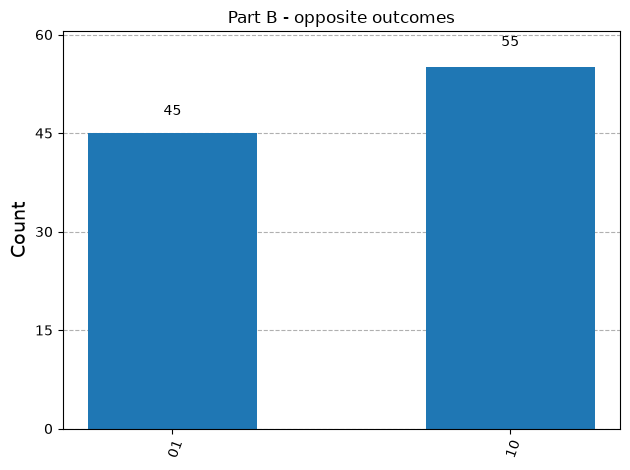

In [5]:
counts_b = run(qc_b)
print("Part B counts (100 shots):", counts_b)
plot_histogram(counts_b, title="Part B - opposite outcomes")

## Part C - Comparison
Both histograms on the same axes, with all four outcomes shown (missing outcomes count as 0).

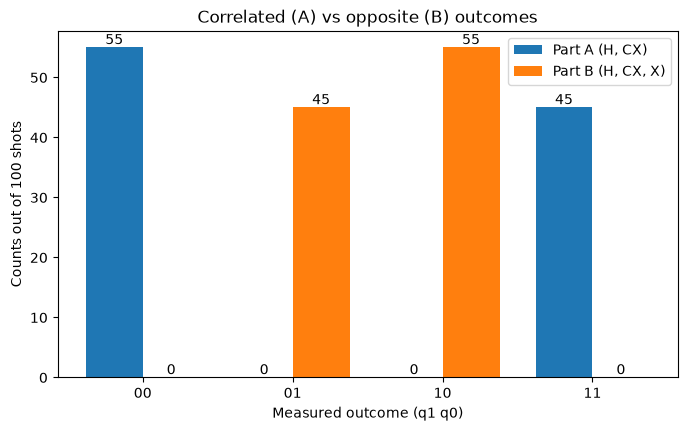

In [6]:
labels = ["00", "01", "10", "11"]
a = [counts_a.get(k, 0) for k in labels]
b = [counts_b.get(k, 0) for k in labels]

x = list(range(len(labels)))
w = 0.38
fig, ax = plt.subplots(figsize=(8, 4.5))
bars_a = ax.bar([i - w / 2 for i in x], a, w, label="Part A (H, CX)")
bars_b = ax.bar([i + w / 2 for i in x], b, w, label="Part B (H, CX, X)")
ax.bar_label(bars_a)
ax.bar_label(bars_b)
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_xlabel("Measured outcome (q1 q0)")
ax.set_ylabel("Counts out of 100 shots")
ax.set_title("Correlated (A) vs opposite (B) outcomes")
ax.legend()
plt.show()

In [7]:
print(f"{'Outcome':<10}{'Part A':>8}{'Part B':>8}")
for k, ca, cb in zip(labels, a, b):
    print(f"{k:<10}{ca:>8}{cb:>8}")

for name, c in [("A", counts_a), ("B", counts_b)]:
    same = c.get("00", 0) + c.get("11", 0)
    diff = c.get("01", 0) + c.get("10", 0)
    print(f"\nPart {name}: same-bit outcomes (00+11) = {same}, different-bit outcomes (01+10) = {diff}")

Outcome     Part A  Part B
00              55       0
01               0      45
10               0      55
11              45       0

Part A: same-bit outcomes (00+11) = 100, different-bit outcomes (01+10) = 0

Part B: same-bit outcomes (00+11) = 0, different-bit outcomes (01+10) = 100


## Explanation

**Which outcomes dominate in Part A?** `00` and `11`. The two qubits always give the same bit, so the counts split between these two outcomes (about 50 each, with small random variation), and `01`/`10` should not appear.

**Which outcomes dominate in Part B?** `01` and `10`. The two qubits always give different bits, so the counts split between these two outcomes, and `00`/`11` should not appear.

**What changed between the two circuits?** Exactly one gate: Part B adds an `X` (NOT) gate on qubit 1 after the entangling step. Everything else is identical.

**Why did the measurement relationship change?**
1. `H` on qubit 0 creates an equal superposition of |0> and |1>.
2. `CX` (control = q0, target = q1) copies that choice onto q1 in a quantum way, producing the entangled Bell state (|00> + |11>)/sqrt(2). Each qubit alone is random, but the two always agree. That is Part A.
3. In Part B, `X` on q1 swaps |0> and |1> for that qubit only. |00> becomes |01> and |11> becomes |10>, giving (|01> + |10>)/sqrt(2). The qubits are still perfectly linked, but now they always disagree.

So the `X` gate acts as a **correlation switch**: without it the qubits are correlated, with it they are anti-correlated. The randomness (which of the two allowed outcomes appears on a given shot) is the same in both cases; only the *relationship* between the two bits changes.

*Note:* Qiskit prints bit strings as `q1 q0` (qubit 0 is the rightmost bit). This does not affect the conclusions here because both allowed outcomes in each part are symmetric.